# 08B.1 — Football outcome reliability and context

**Objective O2 — measurement validity.** Do the approved football outcomes hold stable athlete-level differences, given repeated games, position and observed opportunities?

- Reliability is estimated between **whole games** (odd / even, random game halves, first-N versus later games) — plays of one game never sit in both halves.
- Context (route, alignment, target status) is studied with parameters fitted on **other athletes**; conditioning changes the estimand and is reported as a sensitivity.
- No Combine value is read. NFL context is never a pre-draft predictor.

Reliability says athletes differ stably in the *recorded* outcome. It does not say the outcome is a skill of the athlete alone.

**Gate.** This notebook refuses to run unless 08B.0 recorded a decision whose branch is *frozen* or *exploratory*.

**Prerequisites (same `RUN_MODE`).** 05A, 05B (frozen), 06A, 08A.2, 08B.0.

In [3]:
RUN_MODE = 'full'             # 'smoke' | 'full'
SEED = 20261011
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
EXPERIMENT_VERSION = '08B1.1'
REGISTRY_VERSION = 'v1'       # the registry version recorded in 08B.0
SHOW_TABLES = True

In [4]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import time

import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.tables import LayerRefs
from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import football_figures as ff
from nflbdb.research.advanced_movement import football_registry as fr
from nflbdb.research.advanced_movement import football_reliability as frl
from nflbdb.research.advanced_movement import football_validation as fv
from nflbdb.research.advanced_movement import nfl_outcomes as no
from nflbdb.research.advanced_movement import opportunity_validation as ov
from nflbdb.research.advanced_movement import outcome_semantics as osm
from nflbdb.research.advanced_movement import transfer as tr
from nflbdb.research.advanced_movement.artifacts import FootballStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = FootballStore(cfg, controls)
S8, refs = store.scouting, LayerRefs(cfg)
amc.seed_everything(controls.seed)
NB = {'05A': '05a_nfl_movement_outcome_eda.ipynb', '08A2': '08a2_outcome_semantics_and_opportunity_validation.ipynb',
      '08B0': '08b0_outcome_resolution_and_freeze.ipynb', '08B1': '08b1_football_outcome_reliability.ipynb'}

# ---- GATE: the registry of 08B.0 decides whether anything below may run
REGISTRY, BRANCH = fr.require_branch(store, REGISTRY_VERSION)
TARGETS = fr.targets_of(REGISTRY)
PRIMARY = fr.targets_of(REGISTRY, 'primary')[0]['target_id']
TARGET_IDS = [t['target_id'] for t in TARGETS]
vc = ov.ValidationConfig(**{k: (tuple(v) if isinstance(v, list) else v) for k, v in REGISTRY['config'].items() if k != 'validation_version'})
rc = frl.ReliabilityConfig().for_mode(controls.smoke)
assert REGISTRY['denominators_hash'] == ov.denominators_hash() and REGISTRY['semantics_hash'] == osm.definition_hash(), \
    'the declarations changed since the registry was recorded: record a NEW registry version in 08B.0'

# ---- sensitivity definitions analysed beside the approved ones (never promoted here)
EXTRA = []
if any(k.startswith('FO01') for k in TARGET_IDS):
    EXTRA += ['FO01.S0T', 'FO01.S0N']
if any(k.startswith('FO13') for k in TARGET_IDS):
    EXTRA += ['FO13.K0', 'FO13.K1', 'FO13.K2']
ALL_DEFS = list(dict.fromkeys([*TARGET_IDS, *EXTRA]))

# ---- NFL player-plays of 05A + the audited vendor fields (as in 08A.2; read only)
t0 = time.perf_counter()
registry_m05, freeze_audit = tr.audit_freeze(store.nfl, controls.run_mode)
tr.assert_frozen(freeze_audit)
_, ocfg = tr.frozen_targets(registry_m05)
plays = store.nfl.require(no.plays_contract(ocfg), NB['05A'])
PLAYS_FILE, PP_FILES = store.nfl.parquet(no.plays_contract(ocfg)), list(refs.files('silver', 'player_play'))
base, DUP = osm.semantic_base(plays, refs.scan('silver', 'player_play'))
links, funnel = S8.require(ov.LINKS, NB['08A2']), S8.require(ov.FUNNEL, NB['08A2'])
athletes_08a2 = S8.require(ov.ATHLETES, NB['08A2'])
DRAFT_YEAR = {int(i): int(y) for i, y in links.select('nfl_id', 'draft_year').unique(subset='nfl_id').drop_nulls().iter_rows()}

PARAMS = {'experiment_version': EXPERIMENT_VERSION, 'registry_hash': REGISTRY['version_hash'], 'validation': vc.params(), 'definitions': ALL_DEFS,
          'obs_grid': list(rc.obs_grid), 'crossfit_folds': rc.crossfit_folds}
PROV = {'notebook': NB['08B1'], **PARAMS, 'run_mode': controls.run_mode, 'seed': vc.seed, 'branch': BRANCH['name']}
save = lambda df, contract: store.write(df, contract, '08B1', PROV) if controls.save_tables else df

label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · registry `{REGISTRY["version"]}` (`{REGISTRY["version_hash"]}`) · **{BRANCH["label"]}** · '
                 f'primary `{PRIMARY}` · targets {TARGET_IDS} · sensitivity definitions {EXTRA}'))
print(f'semantic base built in {time.perf_counter() - t0:.0f} s · {base.height:,} player-plays · vendor rows {DUP}')
display(store.describe())

**Run mode: `full`** (FULL) · registry `v1` (`475f557b0f0a0685`) · **EXPLORATORY — source semantics inferred; definitions locked** · primary `FO01.S0` · targets ['FO01.S0', 'FO12.T2', 'FO13.K0'] · sensitivity definitions ['FO01.S0T', 'FO01.S0N', 'FO13.K0', 'FO13.K1', 'FO13.K2']

semantic base built in 1 s · 251,089 player-plays · vendor rows {'n_vendor_rows': 314197, 'n_player_plays': 314197, 'n_duplicate_rows': 0, 'n_conflicting_rows': 0}


what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


## 1 · Synthetic checks

Whole-game halves, exposure thresholds, ranking stability, isolation of the context conditioning (an athlete's own rows never enter the parameters applied to him), Gate B.

In [5]:
validation = fv.run_all(fv.CHECKS_RELIABILITY)
with pl.Config(fmt_str_lengths=200, tbl_rows=-1):
    display(validation)
fv.assert_all_passed(validation)

check,status,detail
str,str,str
"""whole_game_halves_and_reliability""","""PASS""","""halves are whole games; planted trait reliability 0.98, noise-only below 0.7"""
"""exposure_thresholds_and_ranking_stability""","""PASS""","""thresholds are monotone in coverage; ranking stability reported with percentile shifts"""
"""context_conditioning_isolation""","""PASS""","""context parameters come from other athletes; route effect removed (2.04 → 0.00 yd); missing labels fall back"""
"""gate_b_measurement""","""PASS""","""Gate B: PASS for a reliable supported outcome, not for noise or for insufficient linked support"""


## 2 · Outcome rows and game-split reliability

For each approved definition (and its sensitivity definitions): one row per recorded player-play with the context labels that exist, then

- odd / even games (athlete bootstrap) and random game halves, pooled (position-centred) and by position;
- first-N games versus all later games, and reliability among athletes with at least G games;
- reliability against the number of observations required in each game half;
- ranking stability: how far a within-position percentile moves between the two halves;
- the athlete value with its game-bootstrap interval.

The rows are persisted (`football_outcome_rows`) so that 08B.2 and 08B.3 use exactly the same observations.

In [6]:
ROWS = {k: frl.outcome_rows(base, k, vc) for k in ALL_DEFS}
ROWS = {k: r for k, r in ROWS.items() if r is not None and r.height}
missing = [k for k in TARGET_IDS if k not in ROWS]
assert not missing, f'approved definitions without a row: {missing}'

def _suite():
    t1 = time.perf_counter()
    out = frl.reliability_suite(ROWS, vc, rc, progress=lambda m: print(f'[{time.perf_counter() - t1:5.0f} s] {m}'))
    return {**out, frl.ROWS.name: frl.rows_frame(ROWS)}

CONTRACTS = [frl.REL, frl.FIRST_N, frl.THRESH, frl.RANKS, frl.ATHLETES, frl.ROWS]
suite = store.build('08b1_reliability', CONTRACTS, _suite, params=PARAMS, files=[PLAYS_FILE, *PP_FILES])
rel, first_n, thresh, ranks, athletes = (suite[c.name] for c in CONTRACTS[:5])

# the approved rows must be the population 08A.2 screened (same counts, same support)
chk = (athletes.filter(pl.col('denominator_id') == PRIMARY).select('nfl_id', 'n_obs', 'supported')
       .join(athletes_08a2.filter(pl.col('denominator_id') == PRIMARY).select('nfl_id', pl.col('n_obs').alias('n08'), pl.col('supported').alias('s08')), on='nfl_id', how='full'))
print(f'{PRIMARY}: {chk.height} athletes · identical observation counts as 08A.2: {bool((chk["n_obs"] == chk["n08"]).all())} · identical support: {bool((chk["supported"] == chk["s08"]).all())}')
if SHOW_TABLES:
    with pl.Config(tbl_rows=-1, tbl_width_chars=240, fmt_str_lengths=80):
        display(rel.filter(pl.col('denominator_id').is_in(TARGET_IDS)).select('denominator_id', 'split', 'position_group', 'n_athletes', 'r_half', 'rel_sb', 'rel_lo', 'rel_hi', 'note'))
        display(first_n.filter(pl.col('denominator_id') == PRIMARY))
        display(ranks.filter(pl.col('definition_id').is_in(TARGET_IDS)))

21:49:27 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:08b1_reliability] computing (never run)


[    0 s] FO01.S0: 37,398 rows · 116 athletes · 2,528 athlete-games
[    1 s] FO12.T2: 114,277 rows · 194 athletes · 3,697 athlete-games
[    1 s] FO13.K0: 28,962 rows · 98 athletes · 1,917 athlete-games
[    2 s] FO01.S0T: 7,733 rows · 107 athletes · 1,987 athlete-games
[    2 s] FO01.S0N: 29,665 rows · 116 athletes · 2,497 athlete-games
[    2 s] FO13.K1: 27,058 rows · 98 athletes · 1,909 athlete-games


21:49:30 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b1_reliability] football_reliability_game_splits: 30 rows → warehouse/gold/advanced_movement/football_v1/football_reliability_game_splits.parquet
21:49:30 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b1_reliability] football_reliability_exposure: 56 rows → warehouse/gold/advanced_movement/football_v1/football_reliability_exposure.parquet
21:49:30 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b1_reliability] football_reliability_vs_opportunities: 90 rows → warehouse/gold/advanced_movement/football_v1/football_reliability_vs_opportunities.parquet
21:49:30 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b1_reliability] football_ranking_stability: 15 rows → warehouse/gold/advanced_movement/football_v1/football_ranking_stability.parquet
21:49:30 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b1_reliability] football

[    3 s] FO13.K2: 50,363 rows · 98 athletes · 1,953 athlete-games


21:49:30 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b1_reliability] football_outcome_rows: 295,456 rows → warehouse/gold/advanced_movement/football_v1/football_outcome_rows.parquet


FO01.S0: 116 athletes · identical observation counts as 08A.2: True · identical support: True


denominator_id,split,position_group,n_athletes,r_half,rel_sb,rel_lo,rel_hi,note
str,str,str,i64,f64,f64,f64,f64,str
"""FO01.S0""","""odd_even""","""ALL""",100,0.59018,0.74228,0.515976,0.870171,""""""
"""FO01.S0""","""random""","""ALL""",100,0.490261,0.654359,0.507038,0.772434,""""""
"""FO01.S0""","""odd_even""","""WR""",74,0.635097,0.776831,0.446146,0.904701,""""""
"""FO01.S0""","""random""","""WR""",74,0.545272,0.701678,0.547228,0.839514,""""""
"""FO01.S0""","""odd_even""","""TE""",26,0.453074,0.623608,0.376362,0.852742,""""""
"""FO01.S0""","""random""","""TE""",27,0.363211,0.513393,0.155481,0.80009,""""""
"""FO12.T2""","""odd_even""","""ALL""",173,0.418435,0.589995,0.362341,0.746139,""""""
"""FO12.T2""","""random""","""ALL""",173,0.380998,0.54849,0.416525,0.669431,""""""
"""FO12.T2""","""odd_even""","""DB""",81,0.541123,0.702245,0.434127,0.855319,""""""


denominator_id,mode,level,n_athletes,r,rel_sb
str,str,i64,i64,f64,f64
"""FO01.S0""","""first_n_vs_later""",2,105,0.218895,null
"""FO01.S0""","""first_n_vs_later""",4,102,0.383808,null
"""FO01.S0""","""first_n_vs_later""",6,97,0.511778,null
"""FO01.S0""","""first_n_vs_later""",8,91,0.547688,null
"""FO01.S0""","""min_games""",4,99,0.589269,0.74156
"""FO01.S0""","""min_games""",8,95,0.59506,0.746128
"""FO01.S0""","""min_games""",12,86,0.762389,0.865176
"""FO01.S0""","""min_games""",16,71,0.754787,0.860261


definition_id,position_group,n_athletes,spearman,mean_abs_pct_shift,p90_abs_pct_shift,top_group_retention,top_share
str,str,i64,f64,f64,f64,f64,f64
"""FO01.S0""","""ALL""",100,0.58902,19.193347,41.933472,0.538462,0.25
"""FO01.S0""","""WR""",74,0.608589,17.932798,39.864865,0.631579,0.25
"""FO01.S0""","""TE""",26,0.532308,22.781065,40.384615,0.285714,0.25
"""FO12.T2""","""ALL""",173,0.434718,23.314376,51.521739,0.534884,0.25
"""FO12.T2""","""DB""",81,0.517472,21.292486,41.975309,0.6,0.25
"""FO12.T2""","""DL""",92,0.362327,25.094518,57.065217,0.478261,0.25
"""FO13.K0""","""ALL""",89,0.520046,17.939654,44.94382,0.409091,0.25


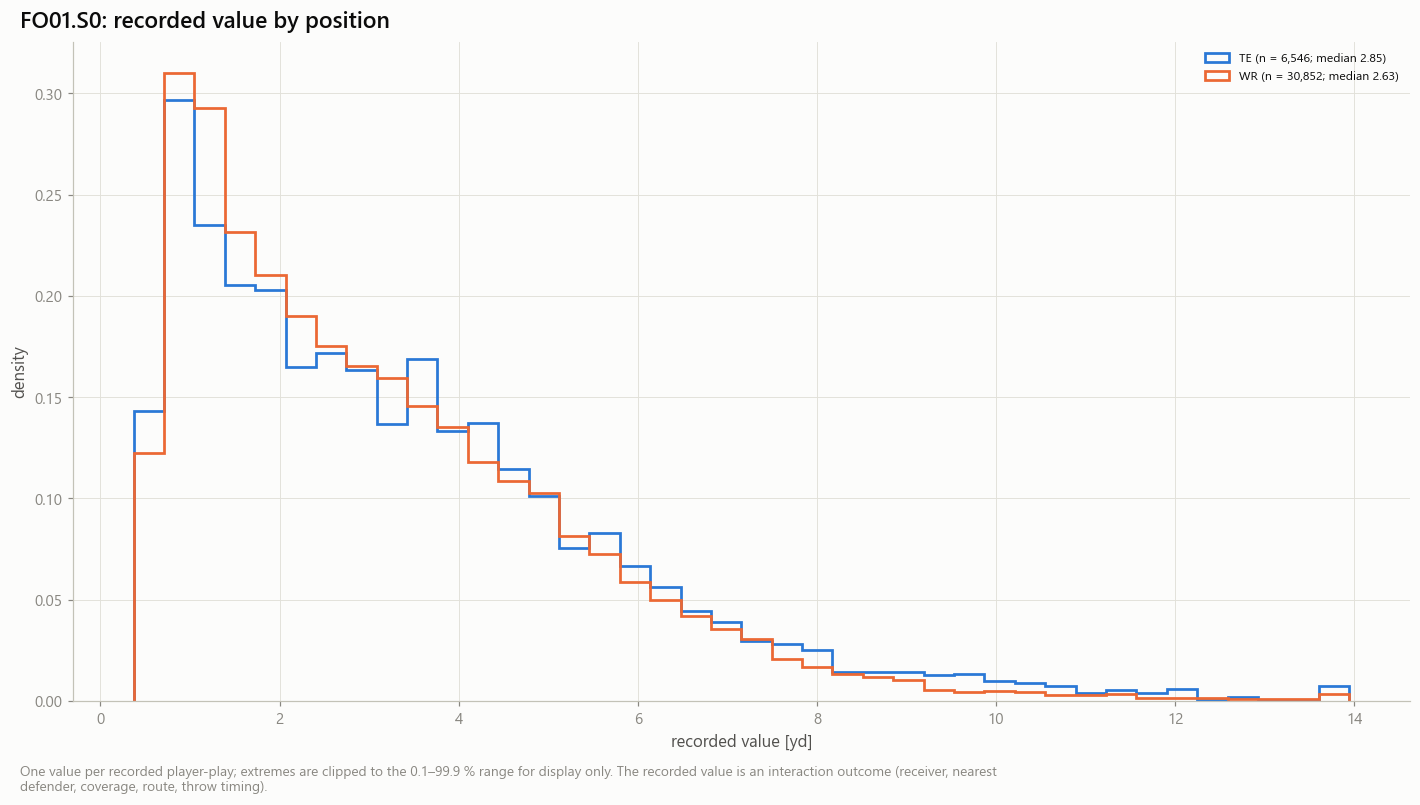

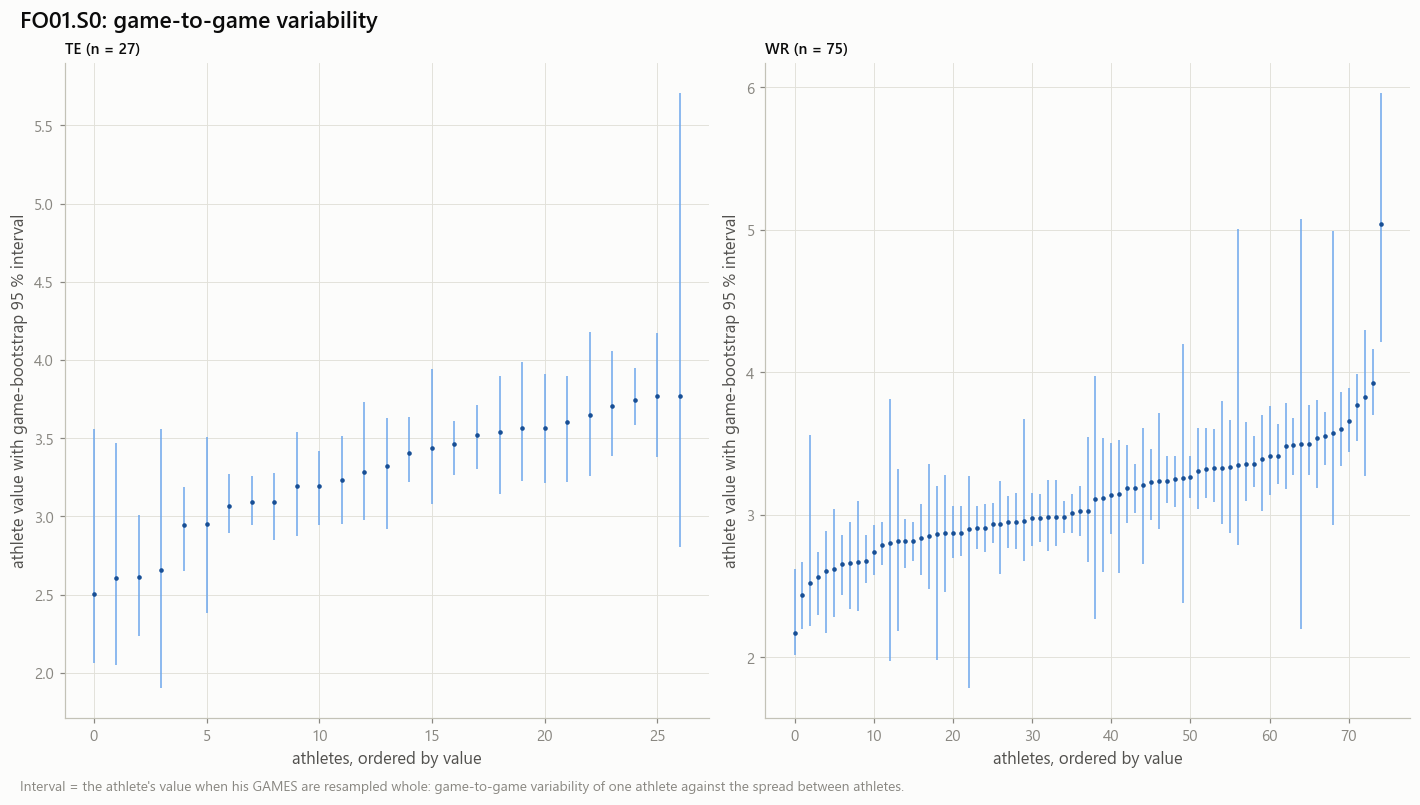

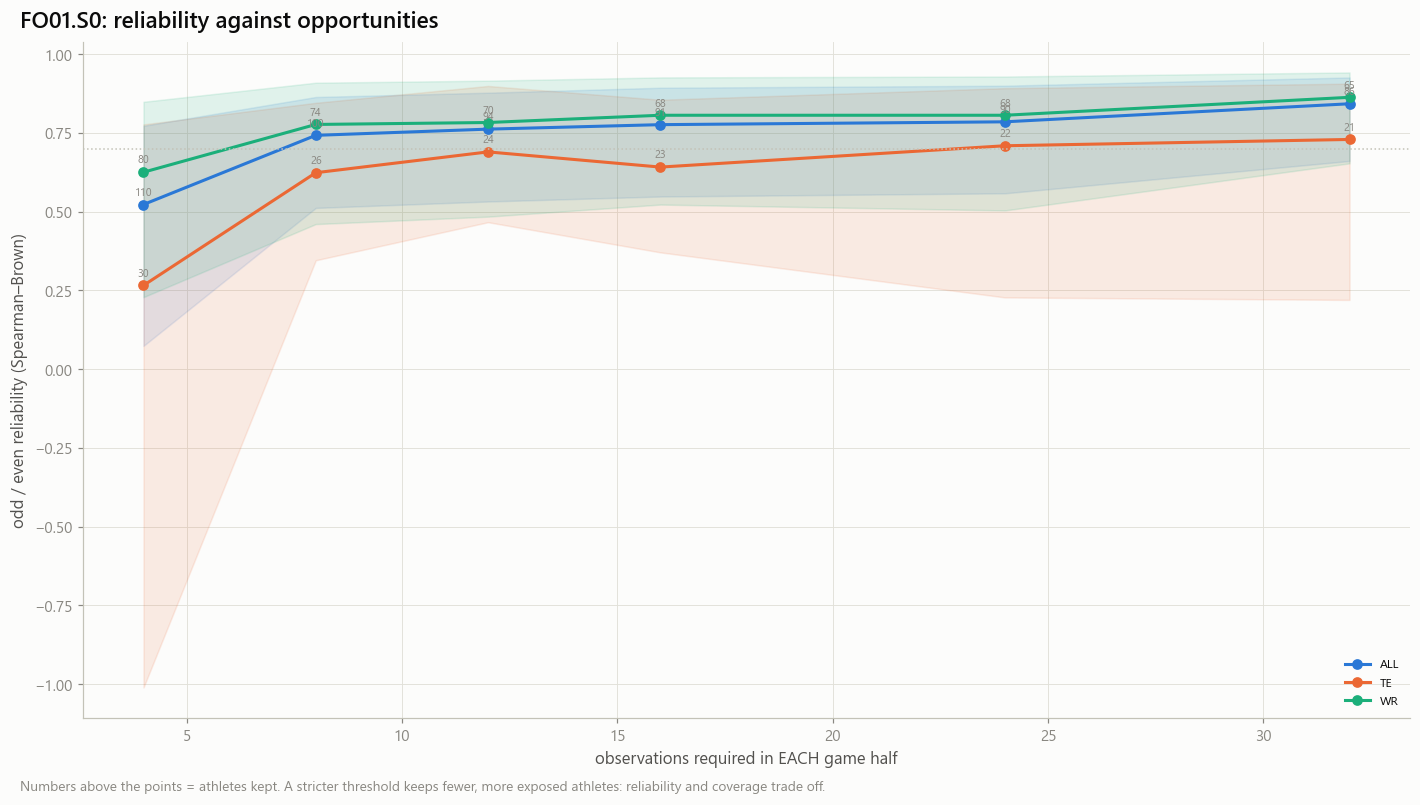

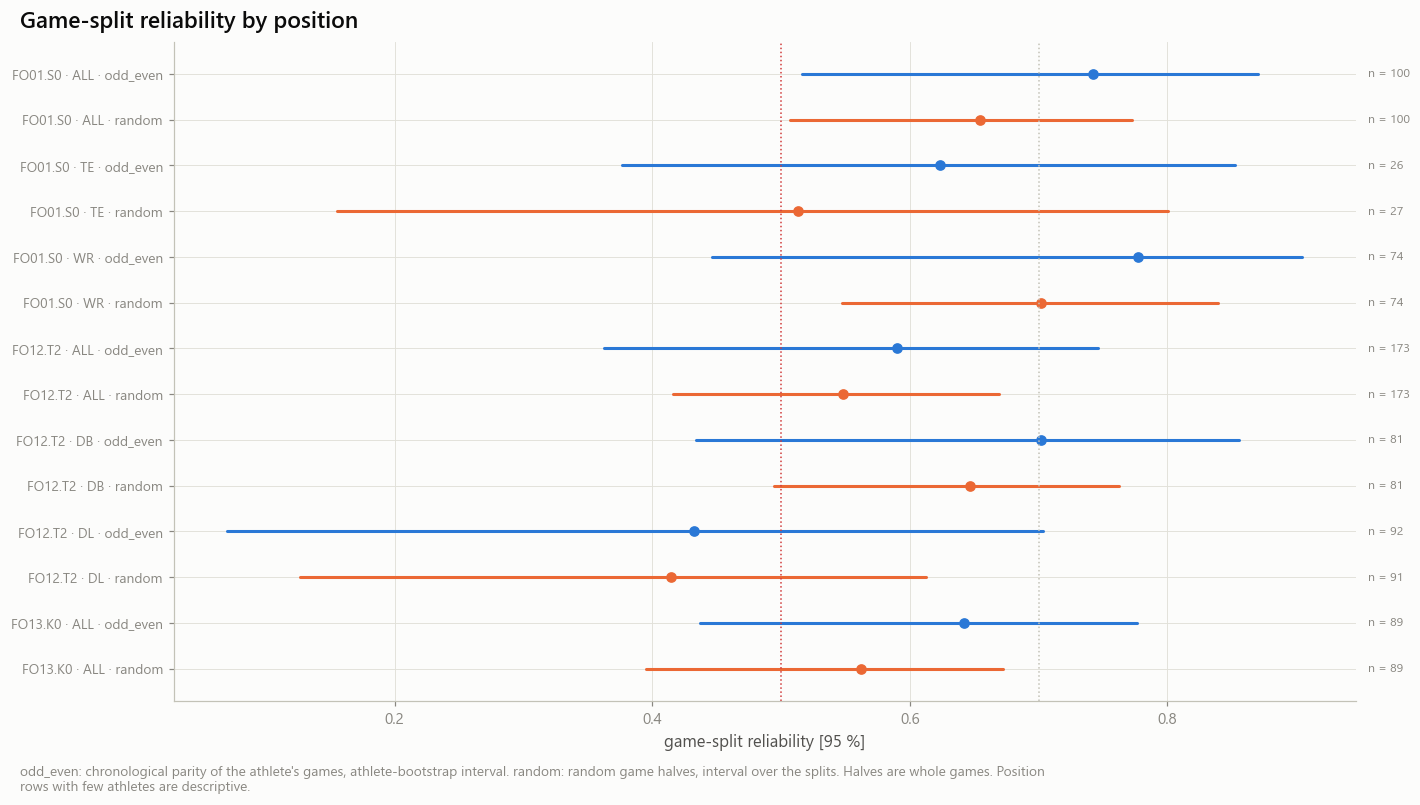

In [7]:
unit = fr.targets_of(REGISTRY, 'primary')[0]['units']
store.show(ff.fig_distribution(ROWS[PRIMARY], 'position_group', f'{PRIMARY}: recorded value by position', f'recorded value [{unit}]'),
           'AM08B1_01_outcome_distribution_by_position', {}, publication=True, source='football_outcome_rows', n='recorded player-plays')
store.show(ff.fig_athlete_intervals(athletes, PRIMARY), 'AM08B1_02_game_to_game_variability', {'athletes': athletes.filter(pl.col('denominator_id') == PRIMARY)},
           source='football_athlete_outcomes', n='supported athletes')
store.show(ff.fig_reliability_vs_obs(thresh, PRIMARY, vc.reliability_ref), 'AM08B1_05_reliability_versus_opportunities', {'thresholds': thresh}, publication=True,
           source='football_reliability_vs_opportunities', n='athletes kept at each threshold')
store.show(ff.fig_reliability_by_position(rel, TARGET_IDS, vc.reliability_ref, vc.reliability_floor), 'AM08B1_06_reliability_by_position', {'reliability': rel},
           publication=True, source='football_reliability_game_splits', n='athletes with enough observations in each half')

## 3 · FO01 — target status, route and alignment

**Targeted versus non-targeted.** The quarterback throws to the open receiver, so target status depends on the outcome: it is shown as a split, never used as a filter of the approved target and never as a predictor.

**Context conditioning** (cross-fitted between athletes):

| Context | What it removes | Consequence |
|---|---|---|
| R0 raw | nothing | the approved estimand |
| R1 route | route mix | partly a property of the player and of his usage |
| R2 route × alignment | also the NFL alignment | a role the team chose |
| R3 target status | the quarterback's choice | outcome-dependent: sensitivity only |

A row without a route label is never assigned one: it falls back to the coarser mean. No conditioned definition replaces the approved one because its reliability or ranking looks better.

21:49:44 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:08b1_context] computing (never run)
21:49:45 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b1_context] football_context_conditioning: 4 rows → warehouse/gold/advanced_movement/football_v1/football_context_conditioning.parquet
21:49:45 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b1_context] football_context_athlete_values: 408 rows → warehouse/gold/advanced_movement/football_v1/football_context_athlete_values.parquet
21:49:45 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08b1_context] football_context_cells: 54 rows → warehouse/gold/advanced_movement/football_v1/football_context_cells.parquet
21:49:45 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B1] football_targeted_versus_not: 3 rows → warehouse/gold/advanced_movement/football_v1/football_targeted_versus_not.parquet


position_group,n_athletes,mean_targeted,mean_not_targeted,mean_difference,r_between,rel_targeted,rel_not_targeted,share_rows_targeted
str,i64,f64,f64,f64,f64,f64,f64,f64
"""ALL""",89,3.791723,3.021985,0.769738,0.685594,0.628493,0.331303,0.206776
"""TE""",22,4.308033,3.13497,1.173063,0.620095,0.280533,-0.299063,0.200428
"""WR""",67,3.622188,2.984886,0.637302,0.696928,0.701476,0.550733,0.208123


definition_id,context_id,context,estimand_change,n_rows,share_rows_supported_cell,n_athletes,row_variance_removed,rel_sb,rel_lo,rel_hi,spearman_vs_raw,mean_abs_pct_shift_vs_raw
str,str,str,str,i64,f64,i64,f64,f64,f64,f64,f64,f64
"""FO01.S0""","""R0""","""raw (no conditioning)""","""the approved estimand""",37398,1.0,102,0.0,0.74228,0.484771,0.874271,1.0,0.0
"""FO01.S0""","""R1""","""route""","""removes route mix — partly a property of the player and of his NFL usage""",37398,0.997353,102,0.119166,0.529061,0.066647,0.770159,0.919142,8.302106
"""FO01.S0""","""R2""","""route × alignment""","""also removes the NFL alignment the team chose""",37398,0.96826,102,0.1235,0.508821,0.123119,0.740809,0.897466,9.490196
"""FO01.S0""","""R3""","""target status""","""conditions on the quarterback's choice, which depends on the outcome: SENSITIVITY ONLY""",37398,1.0,102,0.01975,0.744337,0.536695,0.860422,0.980144,4.075527


definition_id,context_id,cell,n_rows,n_athletes,mean_value,sd_value,supported
str,str,str,i64,i64,f64,f64,bool
"""FO01.S0""","""R2""","""GO × WR""",4456,103,2.45838,1.782342,true
"""FO01.S0""","""R2""","""HITCH × WR""",3568,99,3.033152,1.955835,true
"""FO01.S0""","""R2""","""IN × WR""",2392,98,2.981466,1.822189,true
"""FO01.S0""","""R2""","""CROSS × WR""",2073,94,3.441937,2.252923,true
"""FO01.S0""","""R2""","""GO × SLOT_WR""",1983,104,2.93651,2.023431,true
"""FO01.S0""","""R2""","""HITCH × SLOT_WR""",1980,100,3.250467,2.059177,true
"""FO01.S0""","""R2""","""POST × WR""",1836,93,2.810979,1.774122,true
"""FO01.S0""","""R2""","""CROSS × SLOT_WR""",1803,97,3.035011,2.125212,true
"""FO01.S0""","""R2""","""OUT × WR""",1687,90,3.077789,1.889064,true


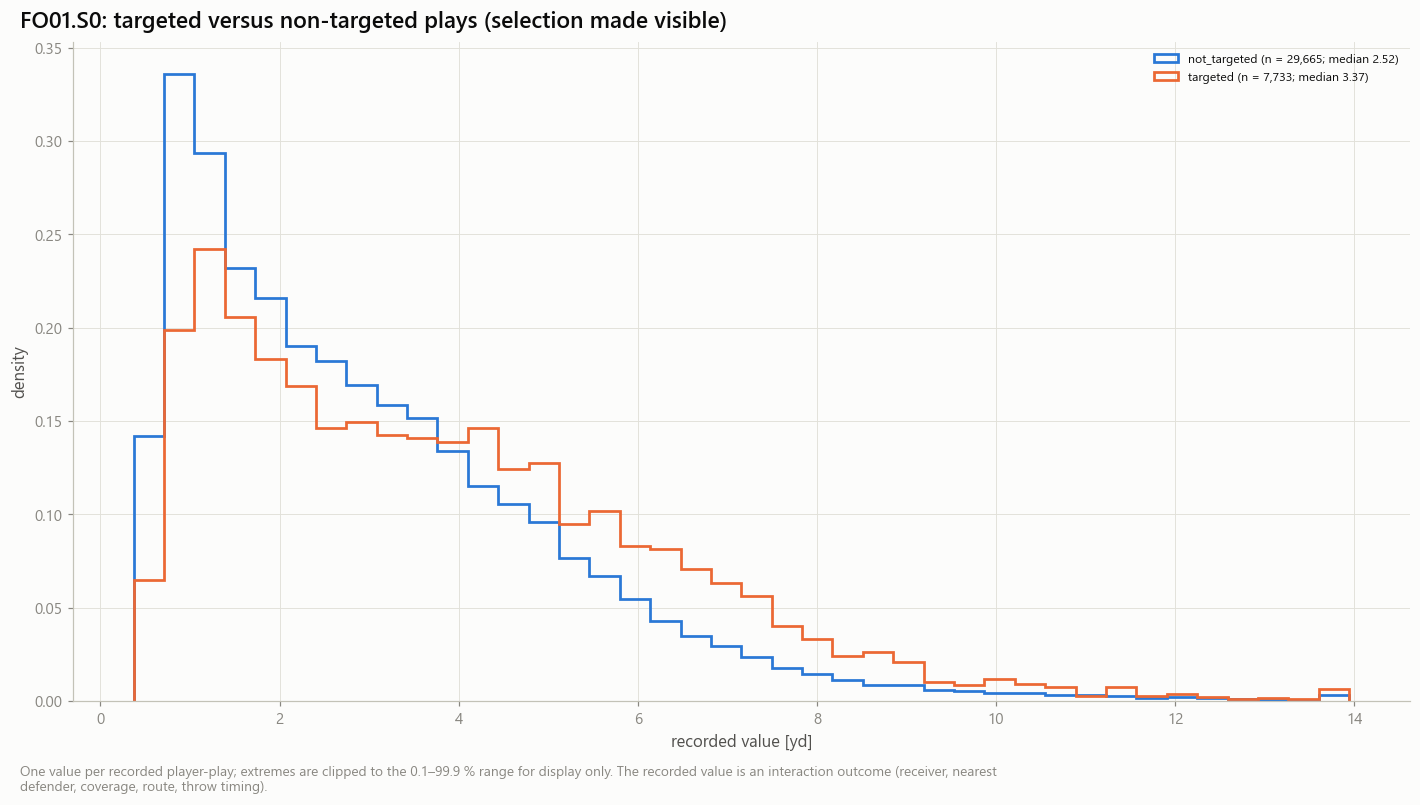

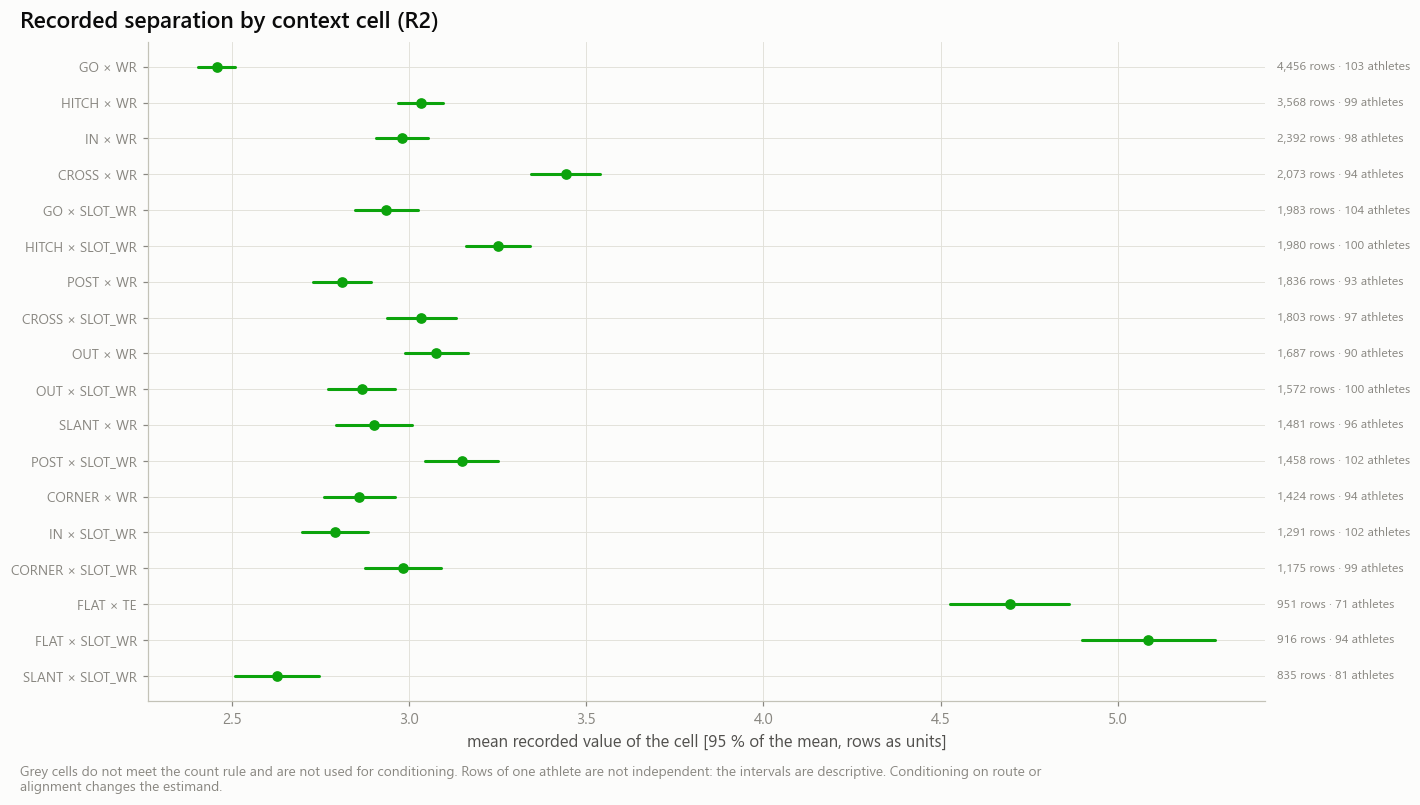

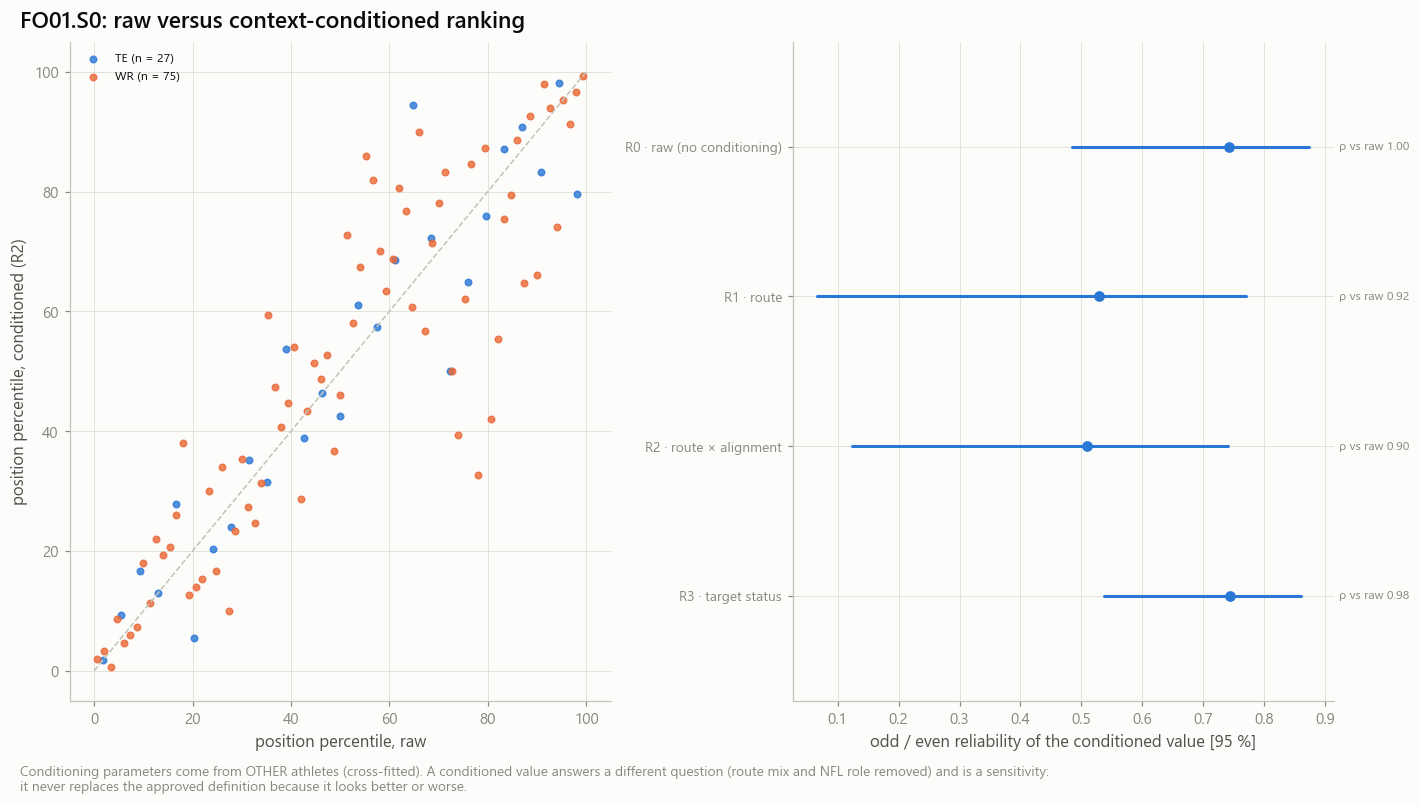

21:49:52 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B1] football_outcome_groups: 35 rows → warehouse/gold/advanced_movement/football_v1/football_outcome_groups.parquet


definition_id,group_kind,group,n_athletes,n_rows,mean_value,sd_athlete,median_games
str,str,str,i64,i64,f64,f64,f64
"""FO01.S0""","""nfl_season""","""2023""",40,7389,3.184995,0.950729,14.0
"""FO01.S0""","""nfl_season""","""2024""",76,13142,3.164621,0.61046,14.0
"""FO01.S0""","""nfl_season""","""2025""",97,16867,3.130311,0.401901,13.0
"""FO01.S0""","""position_group""","""TE""",33,6546,3.356865,0.489304,17.0
"""FO01.S0""","""position_group""","""WR""",83,30852,3.109954,0.451534,17.0
"""FO01.S0""","""draft_cohort""","""2023""",42,21203,3.172426,0.483422,37.5
"""FO01.S0""","""draft_cohort""","""2024""",40,10989,3.125781,0.447724,19.0
"""FO01.S0""","""draft_cohort""","""2025""",34,5206,3.132573,0.439834,15.0
"""FO01.S0""","""games_observed""","""4–7 games""",9,231,3.147064,0.559919,5.0


In [8]:
FO01_TARGETS = [k for k in TARGET_IDS if k.startswith('FO01')]
context = context_values = cells = groups = tsplit = None
if FO01_TARGETS:
    k = FO01_TARGETS[0]
    ctx = store.build('08b1_context', [frl.CONTEXT, frl.CONTEXT_VALUES, frl.CELLS], lambda: frl.context_table(k, ROWS[k], vc, rc), params=PARAMS,
                      files=[store.parquet(frl.ROWS)])
    context, context_values, cells = ctx[frl.CONTEXT.name], ctx[frl.CONTEXT_VALUES.name], ctx[frl.CELLS.name]
    tsplit = save(frl.targeted_split(ROWS.get('FO01.S0T'), ROWS.get('FO01.S0N'), ROWS[k], vc), frl.TARGET_SPLIT)
    if SHOW_TABLES:
        with pl.Config(tbl_rows=-1, tbl_width_chars=240, fmt_str_lengths=120):
            display(tsplit)
            display(context)
            display(cells.filter(pl.col('context_id') == 'R2').head(15))
    store.show(ff.fig_distribution(ROWS[k], 'tgt_label', f'{k}: targeted versus non-targeted plays (selection made visible)', f'recorded value [{unit}]'),
               'AM08B1_03_targeted_versus_not_targeted', {'split': tsplit}, source='football_outcome_rows', n='recorded player-plays with a target flag')
    store.show(ff.fig_cells(cells, 'R2'), 'AM08B1_04_separation_by_route_alignment', {'cells': cells}, source='football_context_cells', n='rows and athletes per cell')
    store.show(ff.fig_context_ranking(context_values, context, k, 'R2'), 'AM08B1_07_raw_versus_context_ranking', {'context': context}, publication=True,
               source='football_context_conditioning', n='supported athletes')
else:
    print('no FO01 definition is approved in the registry: section skipped')
groups = save(pl.concat([frl.group_table(k, ROWS[k], vc, DRAFT_YEAR) for k in TARGET_IDS]), frl.GROUPS)
if SHOW_TABLES:
    with pl.Config(tbl_rows=-1, tbl_width_chars=200):
        display(groups.filter(pl.col('definition_id') == PRIMARY))

## 4 · Secondary outcomes — tackles and sacks, each with its own opportunity definition

Counts and rates of different events are never pooled.

- **Tackles.** How much of a credit rate is assists, and how often a statistic row exists at all. A snap is exposure, not a tackle opportunity.
- **Sacks.** Each sack definition against its own exposure. A rate that follows playing time ranks usage; for a rate target the exposure criterion of Gate B is blocking.

21:49:52 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B1] football_tackle_attribution: 3 rows → warehouse/gold/advanced_movement/football_v1/football_tackle_attribution.parquet
21:49:52 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B1] football_sack_exposure: 3 rows → warehouse/gold/advanced_movement/football_v1/football_sack_exposure.parquet


position_group,n_snaps,n_statistic_rows,n_solo,n_assist,n_both,credits_per_snap,assist_share_of_credits,share_snaps_with_statistic
str,i64,i64,i64,i64,i64,f64,f64,f64
"""ALL""",114277,9243,5613,3627,0,0.080856,0.392532,0.080882
"""DB""",63914,5799,3852,1945,0,0.0907,0.335518,0.090731
"""DL""",50363,3444,1761,1682,0,0.068364,0.488527,0.068384


definition_id,n_athletes,mean_rate,median_rows,rho_value_log_obs,rho_value_games,share_athletes_zero
str,i64,f64,f64,f64,f64,f64
"""FO13.K0""",87,0.008397,196.0,0.600958,0.520695,0.298851
"""FO13.K1""",87,0.008831,194.0,0.608519,0.523854,0.298851
"""FO13.K2""",91,0.004712,326.0,0.610402,0.562624,0.32967


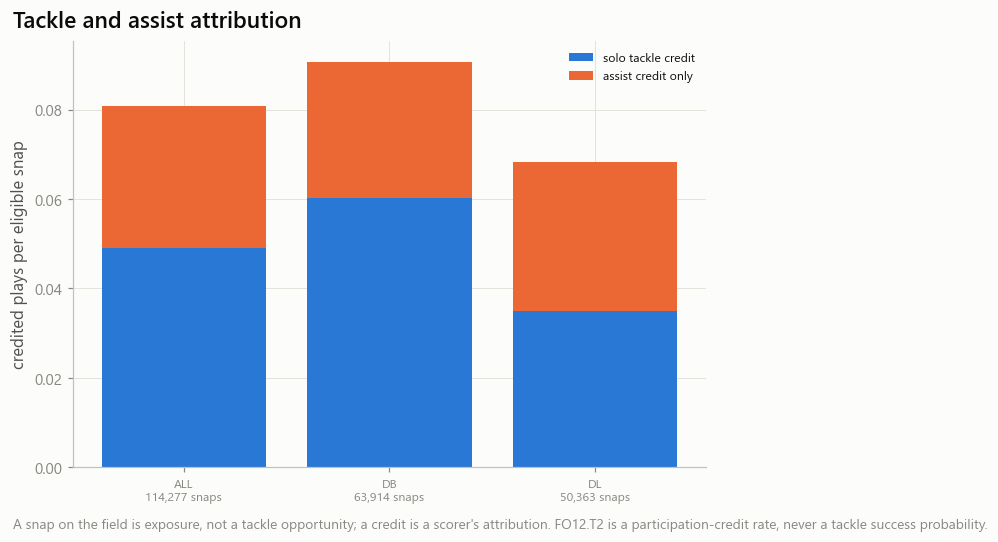

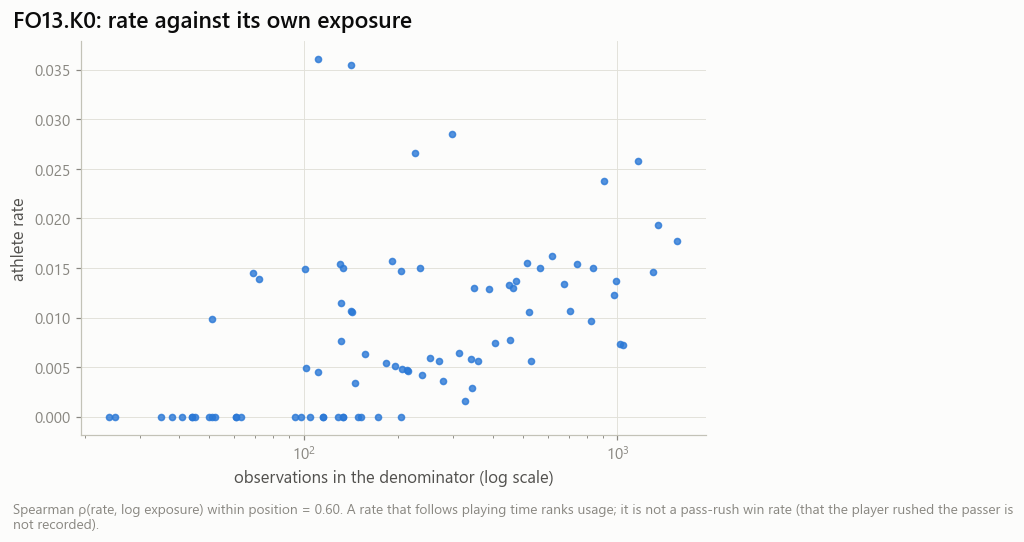

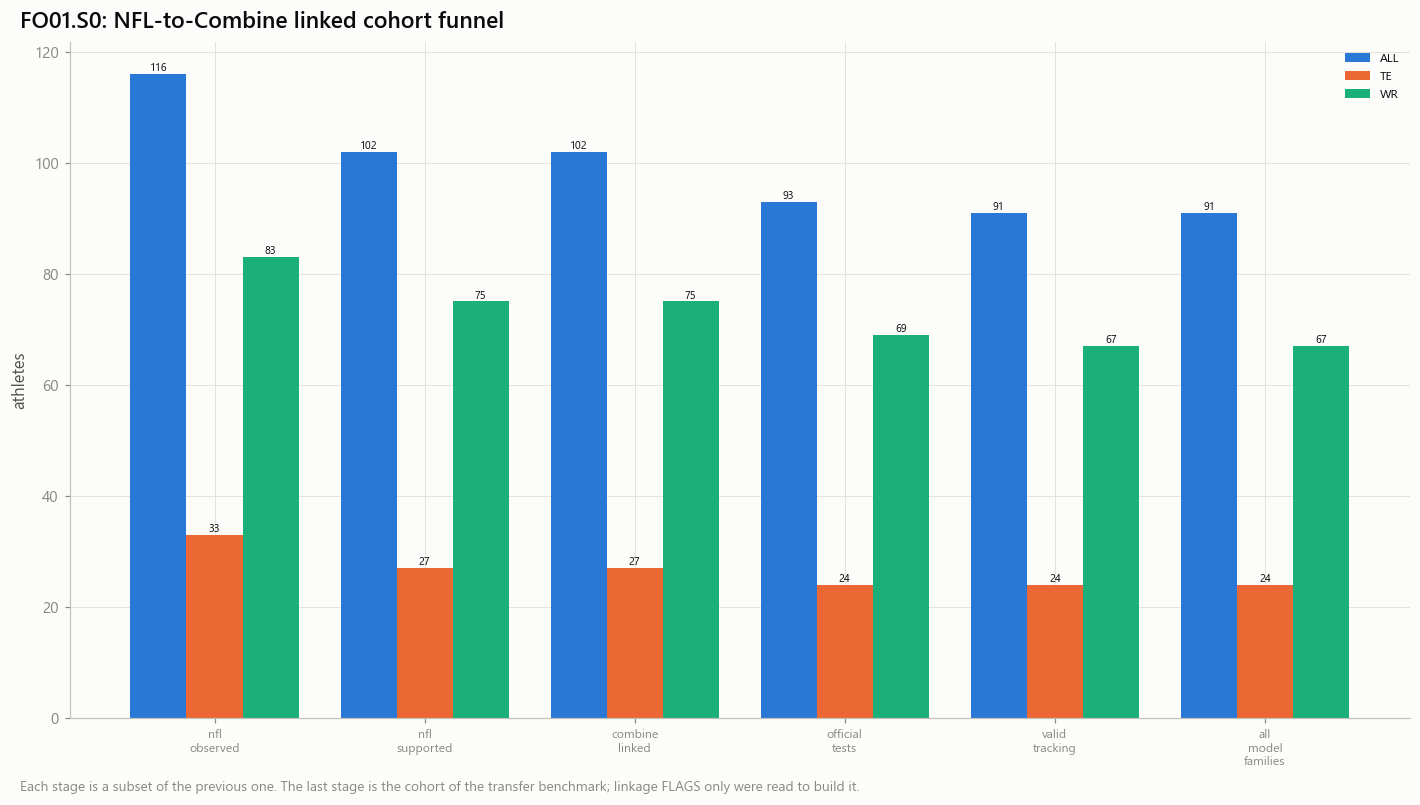

In [9]:
attribution = save(frl.attribution_table(base), frl.ATTRIBUTION)
sack = save(frl.sack_exposure_table(athletes), frl.SACK)
if SHOW_TABLES:
    with pl.Config(tbl_rows=-1, tbl_width_chars=220):
        display(attribution)
        display(sack)
store.show(ff.fig_attribution(attribution), 'AM08B1_08_tackle_assist_attribution', {'attribution': attribution}, source='football_tackle_attribution',
           n='eligible defensive snaps')
SACK_DEF = next((k for k in ('FO13.K0', 'FO13.K2') if k in ROWS), None)
if SACK_DEF:
    store.show(ff.fig_rate_vs_exposure(athletes, SACK_DEF, sack), 'AM08B1_09_sack_exposure_sensitivity', {'sack': sack}, source='football_sack_exposure',
               n='supported athletes')
else:
    print('no sack definition among the analysed definitions: sack exposure figure skipped (the registry does not include FO13)')
store.show(ff.fig_funnel(funnel, PRIMARY), 'AM08B1_10_linked_cohort_funnel', {'funnel': funnel.filter(pl.col('denominator_id') == PRIMARY)}, publication=True,
           source='football_outcome_linked_cohort (08A.2)', n='athletes per stage')

## 5 · Gate B — outcome measurement

Per approved target:

- **PASS** — odd / even reliability at the reference line with a lower bound at the floor, and linked support. The target may carry the primary predictive analysis.
- **WEAK** — reliability at the floor with a positive lower bound: secondary or sensitivity use only.
- **FAIL** — no predictive analysis of this target.

The reference lines are the heuristics declared in 08A.2; they are not tuned here. If the **primary** target is not `PASS`, notebook 08B.2 refuses to run its primary analysis.

In [10]:
gate, GATE_B = frl.gate_b(TARGETS, rel, athletes, links, ranks, vc)
gate = save(gate, frl.GATE_B)
with pl.Config(fmt_str_lengths=200, tbl_rows=-1, tbl_width_chars=260):
    display(gate)
text = frl.conclusions_markdown(gate, GATE_B, rel, context if context is not None else frl.CONTEXT.empty(), vc)
display(Markdown(text))
if controls.save_tables:
    (store.tables_dir / 'football_outcome_reliability_conclusions.md').write_text(text, encoding='utf-8')
    oe = rel.filter((pl.col('split') == 'odd_even') & (pl.col('position_group') == ov.ALL))
    store.write_json('football_reliability_manifest', {
        'experiment_version': EXPERIMENT_VERSION, 'finished_at': utc_now(), 'registry_version': REGISTRY['version'], 'registry_hash': REGISTRY['version_hash'],
        'branch': BRANCH, 'primary': PRIMARY, 'gate_b': GATE_B, 'definitions': list(ROWS),
        'reliability': {r['denominator_id']: {'rel_sb': r['rel_sb'], 'rel_lo': r['rel_lo'], 'rel_hi': r['rel_hi'], 'n_athletes': r['n_athletes']} for r in oe.iter_rows(named=True)},
        'provenance': PROV})
print('Gate B:', GATE_B)

21:49:59 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B1] football_gate_b_measurement: 18 rows → warehouse/gold/advanced_movement/football_v1/football_gate_b_measurement.parquet


target_id,role,criterion,value,passed,blocking
str,str,str,str,bool,bool
"""FO01.S0""","""primary""","""player_level_stability""","""odd / even Spearman–Brown 0.742 (lower bound 0.516); reference 0.7, floor 0.5""",true,true
"""FO01.S0""","""primary""","""opportunity_support""","""91 linked athletes supporting every model family (needed 60)""",true,true
"""FO01.S0""","""primary""","""position_coverage""","""TE 24, WR 67""",true,true
"""FO01.S0""","""primary""","""exposure_independence""","""ρ(value, log observations) = 0.089 (|ρ| ≤ 0.3)""",true,false
"""FO01.S0""","""primary""","""ranking_sensitivity""","""mean |percentile shift| between game halves 19.2""",true,false
"""FO01.S0""","""primary""","""definition_validity""","""source class PROVISIONAL — recorded separation at pass forward, mean over recorded player-plays [yd] — an INTERACTION outcome (receiver, nearest defender, coverage, route, throw timing); NOT pure rece…",true,true
"""FO12.T2""","""secondary""","""player_level_stability""","""odd / even Spearman–Brown 0.59 (lower bound 0.362); reference 0.7, floor 0.5""",false,true
"""FO12.T2""","""secondary""","""opportunity_support""","""141 linked athletes supporting every model family (needed 60)""",true,true
"""FO12.T2""","""secondary""","""position_coverage""","""DB 68, DL 73""",true,true


### 08B.1 — outcome reliability and context

| Target | Gate B | Position | Odd / even reliability [95 %] | Random halves | n |
|---|---|---|---|---|---|
| `FO01.S0` | PASS | ALL | 0.74 [0.52, 0.87] | 0.65 | 100 |
| `FO01.S0` | PASS | WR | 0.78 [0.45, 0.90] | 0.70 | 74 |
| `FO01.S0` | PASS | TE | 0.62 [0.38, 0.85] | 0.51 | 26 |
| `FO12.T2` | WEAK | ALL | 0.59 [0.36, 0.75] | 0.55 | 173 |
| `FO12.T2` | WEAK | DB | 0.70 [0.43, 0.86] | 0.65 | 81 |
| `FO12.T2` | WEAK | DL | 0.43 [0.07, 0.70] | 0.41 | 92 |
| `FO13.K0` | FAIL | ALL | 0.64 [0.44, 0.78] | 0.56 | 89 |

| Definition | Context | Reliability | Rank agreement with raw | Row variance removed | Estimand |
|---|---|---|---|---|---|
| `FO01.S0` | raw (no conditioning) | 0.74 | 1.00 | 0.00 | the approved estimand |
| `FO01.S0` | route | 0.53 | 0.92 | 0.12 | removes route mix — partly a property of the player and of his NFL usage |
| `FO01.S0` | route × alignment | 0.51 | 0.90 | 0.12 | also removes the NFL alignment the team chose |
| `FO01.S0` | target status | 0.74 | 0.98 | 0.02 | conditions on the quarterback's choice, which depends on the outcome: SENSITIVITY ONLY |

- `FO12.T2` fails **player_level_stability**: odd / even Spearman–Brown 0.59 (lower bound 0.362); reference 0.7, floor 0.5
- `FO13.K0` fails **player_level_stability**: odd / even Spearman–Brown 0.642 (lower bound 0.437); reference 0.7, floor 0.5
- `FO13.K0` fails **exposure_independence**: ρ(value, log observations) = 0.601 (|ρ| ≤ 0.3)

Reference lines (heuristics declared in 08A.2): reliability ≥ 0.70 with a lower bound ≥ 0.50; ≥ 60 linked athletes. Reliability says athletes differ stably in the RECORDED outcome; it does not say the outcome is a skill of the athlete alone. Position-level rows (about 24 linked TE) are descriptive, not independent evidence.

Gate B: {'FO01.S0': 'PASS', 'FO12.T2': 'WEAK', 'FO13.K0': 'FAIL'}


## 6 · Reading

- Position rows with few athletes (about 24 linked TE) are descriptive; they are not independent evidence.
- A conditioned definition with lower reliability is not *worse*: route mix and alignment carry stable athlete-level information that the conditioning removes. That is a statement about the estimand, not a defect of the data.
- Reliability is a property of the measurement in this cohort and exposure range. It is not football skill.

**Send back:** checks table, the reliability table, `football_targeted_versus_not`, the context table, Gate B, figures `AM08B1_05`, `06`, `07`.

**Next:** `08b2_football_transfer_benchmark.ipynb` (needs Gate B = PASS for the primary target).